## Tearing sensitivities in $\eta$ and $k$: running $S$-exponents along $\gamma(k)$, and $k_{max}$ by Newton

**Rung 2 (science) of `plans/AUTODIFF_PLAN.md`.** Rung 1b (`tearing-sensitivity.ipynb`) differentiated the
tearing eigenvalue along directions of the *equilibrium* ($\alpha$, the sheet width). Rung 2's overrides seam
(`taranis/overrides.py`) makes the *physics parameters and the wavenumber* differentiable too: the kgrid is
rebuilt by `setup_kgrids(params, overrides=...)` from traced values, so
$$\frac{d\lambda}{dp}=\frac{w^H(\partial J/\partial p)\,v}{w^Hv}$$
with $\partial J/\partial p$ a forward-over-forward `jax.jvp` through the kgrid build and the RHS
(`stability.dj_operator(..., dparams={key: tangent}, overrides=...)`). Here:

* $\partial_\eta$: `dparams={"diss": (0, 1)}` -- `diss` is the $(\nu,\eta)$ pair, so this tangent moves $\eta$ **only**
  ($\nu=0$ stays 0). Local exponent $q_S=d\ln\gamma/d\ln S=-(\eta/\gamma)\,\partial_\eta\gamma$.
* $\partial_k$: `dparams={"Ly": -Ly/k}` -- a mode block is an index, $k_y=2\pi/L_y$, so $dL_y/dk=-L_y/k$.
  $q_k=d\ln\gamma/d\ln k=(k/\gamma)\partial_k\gamma$.
* $\partial_\alpha$ along $dx_0=(\Psi_0,0)$ as in rung 1b.

**The wavenumber is itself an override**: every `Parameters` has the placeholder $L_y=2\pi$ and the block's $k$ is
`overrides={"Ly": 2*pi/k}` -- one compile serves every $k$, and a Newton solve moves $k$ with the box $(L_x,n_x)$ held fixed.

**Setup** (rungs 1b-ref/1b): `dims=2`, $\nu=0$, `hyper=1`, $a=v_{Ay}=1$, $S=1/\eta$, $\Psi_0=\mathrm{sech}^2x$ (+2 images),
$\Phi_0=\alpha\Psi_0$, ky block, fp64. Data: `tearing_rung2_run.py` (every solve one cache file under
`examples/data/tearing-rung2/`); this notebook only reads.

**Which scalings.** For $\Delta'a\propto(ka)^{-n}$ the FKR/Coppi crossing gives $k_{max}\propto S^{-1/(3n+1)}$,
$\gamma_{max}\propto S^{-(n+1)/(3n+1)}$: this sheet has $n=2$, so **$-1/7$ and $-3/7$ already at $\alpha=0$** (rung 1a;
the familiar $-1/4$, $-1/2$ are $n=1$). The paper's eqs. 5.13-5.14 / 8.1 (Mallet, Eriksson, Swisdak & Juno, JPP 2025) give
the SAME $S$-exponents in the shear-modified regime, $k_{tr}a\sim(\alpha/(1-\alpha^2))^{1/7}S^{-1/7}$ (the crossing of the
shear constant-$\psi$ $\gamma\sim\alpha^{1/2}(1-\alpha^2)^{1/2}S^{-1/2}(ka)^{-1/2}$ and nonconstant-$\psi$
$\gamma\sim\alpha^{1/3}(1-\alpha^2)^{2/3}(ka)^{2/3}S^{-1/3}$) and $\gamma_{max}\sim\alpha^{3/7}(1-\alpha^2)^{4/7}S^{-3/7}$, valid for
$1-\alpha^2\ll\alpha$ with a thin layer $\delta_{in}/a=(\alpha/(1-\alpha^2))^{1/3}(kaS)^{-1/3}\ll1$ (eq. 5.15) -- its fig. 4
is at $1-\alpha^2=0.01$, $S=10^8$-$10^{16}$. So the $S$-exponents do **not** discriminate the regimes; what does is the
$\alpha$-dependence and, at fixed $k$, $q_S$: $-3/5$ (FKR) / $-1/3$ (Coppi) without shear, $-1/2$ / $-1/3$ with it.

In [1]:
# fp64 before taranis/jax import (TARANIS_PRECISION is read at import); the profile picks the cache
import os
os.environ["TARANIS_PRECISION"] = "64"
os.environ.setdefault("TARANIS_R2_PROFILE", "full")
import time
import numpy as np
import matplotlib.pyplot as plt
import tearing_eigen_run as T
import tearing_sensitivity_run as U
import tearing_rung2_run as R

t0 = time.time()
FD = R.fd_results()
DISP = {(S, al): R.disp_results(S, al) for S in R.S_DISP for al in R.ALPHA_DISP}
KA = {S: R.kmax_alpha_results(S) for S in R.S_KA}
KS = {al: R.kmax_S_results(al, hi=(al == 0.0)) for al in R.ALPHA_KS}
G2 = R.grid2_results()
print(f"profile {R.PROFILE}: read {sum(len(v.get(1, {})) for v in DISP.values())} dispersion points, "
      f"{sum(len(v) for v in KA.values())} k_max(alpha) and {sum(len(v) for v in KS.values())} k_max(S) "
      f"solutions, {len(FD)} FD points, {len(G2)} 2nx checks in {time.time() - t0:.1f} s")

field variables are using 64bit precision.
profile full: read 192 dispersion points, 48 k_max(alpha) and 31 k_max(S) solutions, 4 FD points, 4 2nx checks in 2.8 s


### 1. Checks: the seam, the theory's analytic exponents, the FD gates

(a) $J$ at `overrides={"Ly": 2π/k}` against $J$ of a `Parameters` built with that $L_y$ (the rung-2 gate, re-checked on this
setup). (b) The exact $\alpha=0$ dispersion relation $\Delta'\delta_\eta=F(\Lambda)$ (rung 1a) differentiated
**analytically**: with $m=d\ln F/d\ln\Lambda=\tfrac54+\tfrac38 b[\psi(\tfrac{b-1}4)-\psi(\tfrac{b+5}4)]$, $b=\Lambda^{3/2}$,
$$q_S=-\tfrac13-\tfrac1{3m},\qquad q_k=\tfrac23+\frac{d\ln\Delta'/d\ln k-\tfrac13}{m},$$
against central differences of $\gamma_{th}$. (c) The sensitivities against central differences of eigenvalues, in $\eta$
(`overrides` moving $\eta$ in the pair) and in $k$, at the sensitivity's own grid.

In [2]:
import taranis as jr
from taranis import stability as st
S_, k_, al_, nx_, Lx_ = 1e4, 0.5, 0.8, 512, 30.0
p = R.make_params(S_, nx_, Lx_)
x0 = U.equilibrium(p, al_)[0]
Jo, _ = st.ky_block_matrix(x0, jr.setup_kgrids(p), p, 1, overrides=R.k_override(k_))
p2 = jr.Parameters(nx=nx_, ny=8, Lx=Lx_, Ly=2*np.pi/k_, dims=2, cfl_safety=0.5, forcing=False,
                   eqpars={"diss": (0.0, 1/S_), "hyper": 1})
Jp, _ = st.ky_block_matrix(U.equilibrium(p2, al_)[0], jr.setup_kgrids(p2), p2, 1)
print(f"(a) max |J(overrides Ly) - J(Parameters Ly)| = {np.abs(Jo - Jp).max():.1e}  (max |J| = {np.abs(Jp).max():.1e})")
print("(b) theory exponents: analytic vs central difference of gamma_theory (h = 1e-4 in ln)")
h = 1e-4
for ka in (0.1, 0.3, 1.0, 2.0):
    for S in (1e3, 1e5):
        fS = (np.log(T.gamma_theory(ka, S*np.exp(h))) - np.log(T.gamma_theory(ka, S*np.exp(-h))))/(2*h)
        fk = (np.log(T.gamma_theory(ka*np.exp(h), S)) - np.log(T.gamma_theory(ka*np.exp(-h), S)))/(2*h)
        print(f"    ka={ka:4.1f} S={S:.0e}: q_S {R.theory_s_exponent(ka, S):+.9f} (FD {fS:+.9f})   "
              f"q_k {R.theory_k_exponent(ka, S):+.7f} (FD {fk:+.7f})")

(a) max |J(overrides Ly) - J(Parameters Ly)| = 0.0e+00  (max |J| = 1.1e-01)
(b) theory exponents: analytic vs central difference of gamma_theory (h = 1e-4 in ln)
    ka= 0.1 S=1e+03: q_S -0.334864997 (FD -0.334864997)   q_k +0.6559457 (FD +0.6559457)
    ka= 0.1 S=1e+05: q_S -0.340377218 (FD -0.340377218)   q_k +0.6173625 (FD +0.6173625)
    ka= 0.3 S=1e+03: q_S -0.352598114 (FD -0.352598114)   q_k +0.5317894 (FD +0.5317894)
    ka= 0.3 S=1e+05: q_S -0.411046192 (FD -0.411046192)   q_k +0.1225805 (FD +0.1225805)
    ka= 1.0 S=1e+03: q_S -0.511914249 (FD -0.511914249)   q_k -0.6905483 (FD -0.6905483)
    ka= 1.0 S=1e+05: q_S -0.581961236 (FD -0.581961236)   q_k -1.2229054 (FD -1.2229054)
    ka= 2.0 S=1e+03: q_S -0.595282869 (FD -0.595282869)   q_k -6.9485806 (FD -6.9485825)
    ka= 2.0 S=1e+05: q_S -0.599246153 (FD -0.599246153)   q_k -7.0637989 (FD -7.0638008)


In [3]:
print("(c) FD gate: central differences of eigenvalues (relative steps h in eta and in k) vs the sensitivity")
print("    S      ka   alpha   nx   | dir |  sensitivity         |  h      |FD - sens|  rel.      | order")
FDROWS = []
for (S, ka, al), (rec, rows) in FD.items():
    for which in ("eta", "k"):
        d = complex(rec["dlam_eta" if which == "eta" else "dlam_k"]).real
        hs = np.array([r[0] for r in rows[which]]); es = np.array([r[2] for r in rows[which]])
        order = np.polyfit(np.log(hs), np.log(es), 1)[0]
        FDROWS.append((S, ka, al, which, order, es[-1]/abs(d)))
        for i, (hh, fd, e) in enumerate(rows[which]):
            head = (f"  {S:.0e}  {ka:4.2f}  {al:4.2f}  {int(rec['nx']):5d}  | {which:3s} | {d:+.12e} |"
                    if i == 0 else " "*43 + "|" + " "*22 + "|")
            print(f"{head} {hh:7.0e}  {e:.2e}  {e/abs(d):.1e}  |" + (f" {order:.3f}" if i == len(rows[which]) - 1 else ""))
    print(f"{'':43s}  gamma = {complex(rec['lam']).real:.10e}, residuals r/l {float(rec['res_r']):.1e}/"
          f"{float(rec['res_l']):.1e}, kappa {float(rec['kappa']):.2e}, rel_err {float(rec['rel_err']):.1e}")

(c) FD gate: central differences of eigenvalues (relative steps h in eta and in k) vs the sensitivity
    S      ka   alpha   nx   | dir |  sensitivity         |  h      |FD - sens|  rel.      | order
  1e+03  0.50  0.00   1024  | eta | +2.691880448041e+01 |   1e-02  5.65e-04  2.1e-05  |
                                           |                      |   3e-03  5.08e-05  1.9e-06  |
                                           |                      |   1e-03  5.65e-06  2.1e-07  | 2.000
  1e+03  0.50  0.00   1024  | k   | +3.932216507546e-02 |   1e-02  2.01e-06  5.1e-05  |
                                           |                      |   3e-03  1.80e-07  4.6e-06  |
                                           |                      |   1e-03  2.01e-08  5.1e-07  | 2.000
                                             gamma = 7.6692771380e-02, residuals r/l 4.6e-15/5.5e-15, kappa 6.20e+00, rel_err 6.2e-13
  1e+04  0.20  0.60   4096  | eta | +6.050901427278e+01 |   1e-02  1.15e-03  1.9e-05 

### 2. The local $S$-exponent along the dispersion curve

$q_S(k)=-(\eta/\gamma)\partial_\eta\gamma$ at every $k$ of a sweep, one sensitivity per point (no sweep in $S$), at
$S=10^3$-$10^5$ and $\alpha=0,0.3,0.6,0.8$; rung 1a's per-$k$ box $L_x=\max(15/k,20)$, $n_x$ from its converged ladders,
every point also at $n_x/2$. At $\alpha=0$ the exact relation's analytic $q_S$ is the reference (it is an asymptotic
theory: agreement is a trend in $S$, the eigenvalue carrying rung 1a's finite-$S$ correction
$\simeq C(k)/(\gamma\tau_R)$, strongest near the marginal point $ka=\sqrt5$).

In [4]:
def disp_curve(S, al, lv=1):
    f = DISP[(S, al)].get(lv, {})
    ka = np.array(sorted(f))
    return ka, [f[k] for k in ka]

print("grid convergence of the sweeps: nx vs nx/2 (max over ka), and the worst residual / isolation")
print("    S     alpha | points | max rel d gamma   max |d q_S|   max |d q_k|  | max res   max rel_err  max kappa")
for (S, al) in sorted(DISP):
    hi, lo = DISP[(S, al)].get(1, {}), DISP[(S, al)].get(2, {})
    com = [k for k in hi if k in lo]
    if not com:
        continue
    dg = max(abs(complex(hi[k]["lam"])/complex(lo[k]["lam"]) - 1) for k in com)
    dqs = max(abs(R.s_exponent(hi[k]) - R.s_exponent(lo[k])) for k in com)
    dqk = max(abs(R.k_exponent(hi[k]) - R.k_exponent(lo[k])) for k in com)
    res = max(max(float(hi[k]["res_r"]), float(hi[k]["res_l"])) for k in hi)
    print(f"  {S:.0e}  {al:4.2f}  |  {len(hi):3d}   |  {dg:.1e}          {dqs:.1e}       {dqk:.1e}     | {res:.1e}   "
          f"{max(float(hi[k]['rel_err']) for k in hi):.1e}      {max(float(hi[k]['kappa']) for k in hi):.1e}")
missing = [(S, al, k) for (S, al) in DISP for k in R.KA_DISP if k not in DISP[(S, al)].get(1, {})]
print(f"\nnot available (refused / failed / not computed): {missing if missing else 'none'}")

grid convergence of the sweeps: nx vs nx/2 (max over ka), and the worst residual / isolation
    S     alpha | points | max rel d gamma   max |d q_S|   max |d q_k|  | max res   max rel_err  max kappa
  1e+03  0.00  |   16   |  5.3e-03          1.4e-03       3.0e+00     | 1.8e-13   9.5e-07      7.7e+01
  1e+03  0.30  |   16   |  2.1e-04          6.5e-04       6.6e-04     | 3.6e-13   3.6e-05      1.1e+04
  1e+03  0.60  |   16   |  5.7e-05          1.7e-04       1.7e-04     | 4.8e-13   1.6e-04      3.2e+04
  1e+03  0.80  |   16   |  1.1e-05          2.6e-05       2.7e-05     | 5.8e-13   4.0e-04      8.0e+04
  1e+04  0.00  |   16   |  2.0e-03          7.0e-03       2.5e-02     | 3.4e-13   1.7e-06      2.0e+02
  1e+04  0.30  |   16   |  1.8e-04          6.9e-04       7.7e-04     | 2.9e-13   2.6e-07      2.3e+04
  1e+04  0.60  |   16   |  2.3e-05          1.1e-04       1.1e-04     | 2.3e-13   2.0e-07      7.3e+04
  1e+04  0.80  |   16   |  7.4e-07          4.1e-06       1.3e-05     | 5.8e-13

In [5]:
print("q_S = d ln gamma/d ln S along gamma(k), alpha = 0: eigen-sensitivity | exact theory (analytic)")
print("   ka  | " + " | ".join(f"   S = {S:.0e}: eig      th   " for S in R.S_DISP))
for ka in R.KA_DISP:
    row = []
    for S in R.S_DISP:
        f = DISP[(S, 0.0)].get(1, {})
        row.append(f"{R.s_exponent(f[ka]):+.4f}  {R.theory_s_exponent(ka, S):+.4f}" if ka in f else " "*16)
    print(f"  {ka:4.2f} |   " + "   |   ".join(row))

q_S = d ln gamma/d ln S along gamma(k), alpha = 0: eigen-sensitivity | exact theory (analytic)
   ka  |    S = 1e+03: eig      th    |    S = 1e+04: eig      th    |    S = 1e+05: eig      th   
  0.10 |   -0.2641  -0.3349   |   -0.3187  -0.3366   |   -0.3359  -0.3404
  0.15 |   -0.2796  -0.3373   |   -0.3268  -0.3417   |   -0.3472  -0.3511
  0.20 |   -0.2904  -0.3410   |   -0.3360  -0.3495   |   -0.3632  -0.3671
  0.30 |   -0.3089  -0.3526   |   -0.3605  -0.3731   |   -0.4071  -0.4110
  0.40 |   -0.3286  -0.3698   |   -0.3925  -0.4052   |   -0.4564  -0.4603
  0.50 |   -0.3510  -0.3916   |   -0.4282  -0.4409   |   -0.4986  -0.5022
  0.60 |   -0.3756  -0.4167   |   -0.4625  -0.4751   |   -0.5290  -0.5326
  0.70 |   -0.4011  -0.4429   |   -0.4917  -0.5042   |   -0.5494  -0.5530
  0.85 |   -0.4372  -0.4803   |   -0.5238  -0.5366   |   -0.5675  -0.5716
  1.00 |   -0.4668  -0.5119   |   -0.5441  -0.5578   |   -0.5773  -0.5820
  1.25 |   -0.4977  -0.5495   |   -0.5611  -0.5780   |   -0.5848 

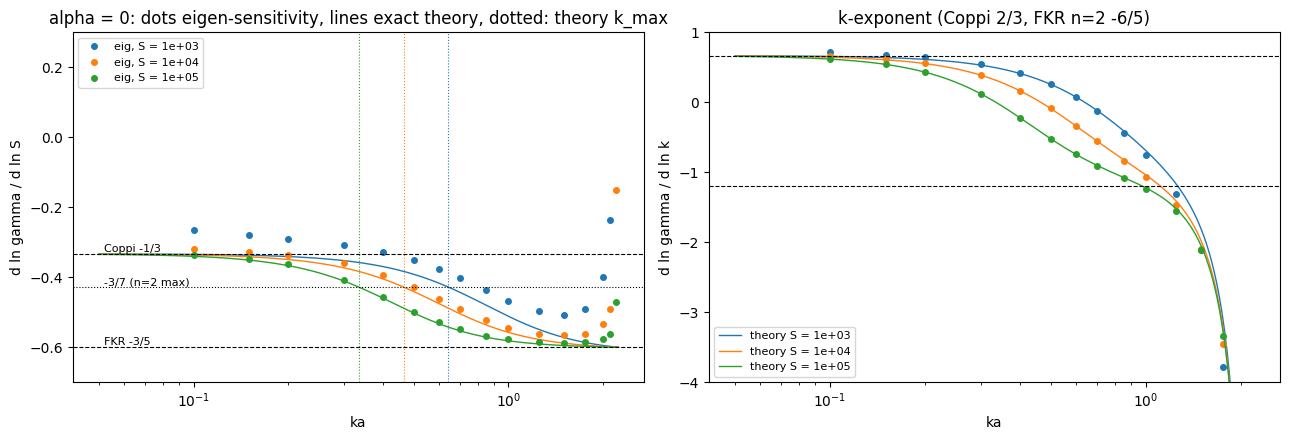

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
for j, S in enumerate(R.S_DISP):
    ka, recs = disp_curve(S, 0.0)
    if len(ka):
        axs[0].semilogx(ka, [R.s_exponent(r) for r in recs], "o", color=f"C{j}", ms=4, label=f"eig, S = {S:.0e}")
    kk = np.geomspace(0.05, 2.23, 200)
    axs[0].semilogx(kk, [R.theory_s_exponent(k, S) for k in kk], "-", color=f"C{j}", lw=1)
    km, _ = R.theory_kmax(S)
    axs[0].axvline(km, color=f"C{j}", ls=":", lw=0.8)
for y, lab in ((-3/5, "FKR -3/5"), (-1/3, "Coppi -1/3"), (-3/7, "-3/7 (n=2 max)")):
    axs[0].axhline(y, color="k", ls="--" if y != -3/7 else ":", lw=0.8)
    axs[0].text(0.052, y + 0.006, lab, fontsize=8)
axs[0].set_xlabel("ka"); axs[0].set_ylabel("d ln gamma / d ln S"); axs[0].set_title("alpha = 0: dots eigen-sensitivity, lines exact theory, dotted: theory k_max")
axs[0].legend(fontsize=8); axs[0].set_ylim(-0.7, 0.3)
for j, S in enumerate(R.S_DISP):
    ka, recs = disp_curve(S, 0.0)
    if len(ka):
        axs[1].semilogx(ka, [R.k_exponent(r) for r in recs], "o", color=f"C{j}", ms=4)
    kk = np.geomspace(0.05, 2.1, 200)
    axs[1].semilogx(kk, [R.theory_k_exponent(k, S) for k in kk], "-", color=f"C{j}", lw=1, label=f"theory S = {S:.0e}")
for y in (2/3, -6/5):
    axs[1].axhline(y, color="k", ls="--", lw=0.8)
axs[1].set_ylim(-4, 1); axs[1].set_xlabel("ka"); axs[1].set_ylabel("d ln gamma / d ln k"); axs[1].legend(fontsize=8)
axs[1].set_title("k-exponent (Coppi 2/3, FKR n=2 -6/5)")
plt.tight_layout()

In [7]:
# the envelope identity at the maximum: q_S at k_max IS d ln gamma_max/d ln S. From the sweep: q_S interpolated
# (quadratic in ln k through the 3 points around the largest gamma) at the sweep's k_max, against the Newton
# solution's -(eta/gamma*) dgamma/deta at k* (section 4) and the theory's
print("   S    | sweep k_max  q_S there | Newton k*   q_S at k*  | theory k_max  q_S(k_max) | n=2 asymptote -3/7")
for S in R.S_DISP:
    ka, recs = disp_curve(S, 0.0)
    if len(ka) < 3:
        continue
    g = np.array([complex(r["lam"]).real for r in recs]); i = int(np.clip(np.argmax(g), 1, len(g) - 2))
    lk = np.log(ka[i - 1:i + 2]); cg = np.polyfit(lk, g[i - 1:i + 2], 2); lkm = -cg[1]/(2*cg[0])
    q = np.polyval(np.polyfit(lk, [R.s_exponent(r) for r in recs[i - 1:i + 2]], 2), lkm)
    nw = KA.get(S, {}).get(0.0)
    kth = R.theory_kmax(S)[0]
    print(f"  {S:.0e} |  {np.exp(lkm):.4f}     {q:+.4f}   | " +
          (f"{nw['kmax']:.6f}   {nw['slope_g_S']:+.5f}  " if nw else " "*23) +
          f"|  {kth:.6f}     {R.theory_s_exponent(kth, S):+.5f}  | {-3/7:+.5f}")

   S    | sweep k_max  q_S there | Newton k*   q_S at k*  | theory k_max  q_S(k_max) | n=2 asymptote -3/7
  1e+03 |  0.6353     -0.3846   | 0.637613   -0.38521  |  0.640696     -0.42731  | -0.42857
  1e+04 |  0.4633     -0.4153   | 0.465551   -0.41584  |  0.464838     -0.42828  | -0.42857
  1e+05 |  0.3312     -0.4224   | 0.335593   -0.42478  |  0.335196     -0.42853  | -0.42857


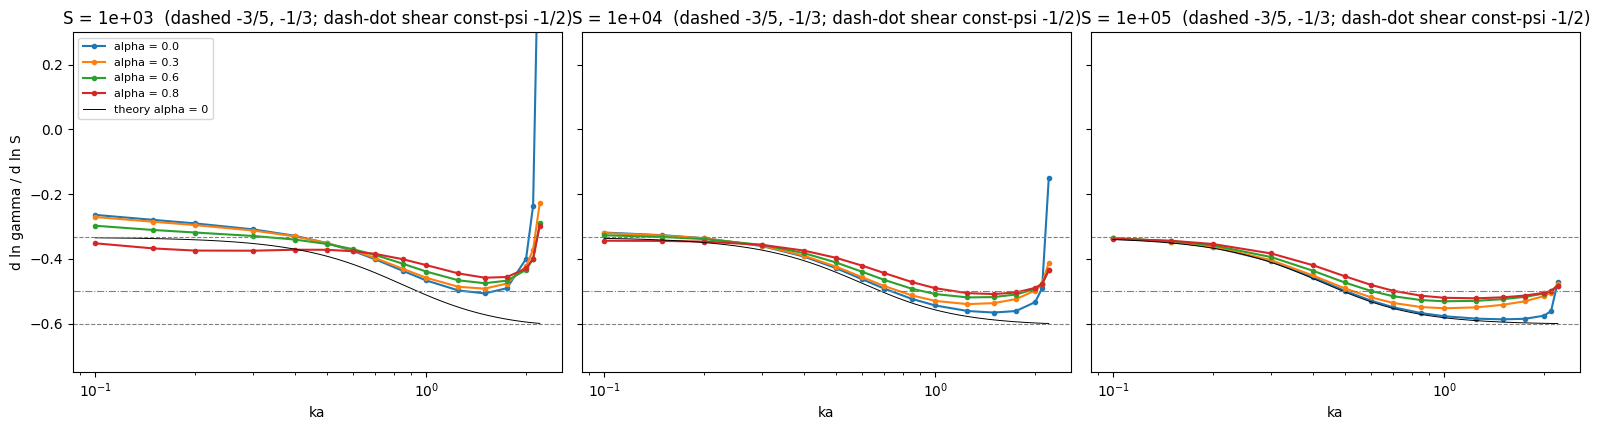

In [8]:
fig, axs = plt.subplots(1, 3, figsize=(16, 4.4), sharey=True)
for ax, S in zip(axs, R.S_DISP):
    for j, al in enumerate(R.ALPHA_DISP):
        ka, recs = disp_curve(S, al)
        if len(ka):
            ax.semilogx(ka, [R.s_exponent(r) for r in recs], "o-", ms=3, color=f"C{j}", label=f"alpha = {al}")
    kk = np.geomspace(0.1, 2.2, 200)
    ax.semilogx(kk, [R.theory_s_exponent(k, S) for k in kk], "k-", lw=0.7, label="theory alpha = 0")
    for y, ls in ((-3/5, "--"), (-1/2, "-."), (-1/3, "--")):
        ax.axhline(y, color="gray", ls=ls, lw=0.8)
    ax.set_title(f"S = {S:.0e}  (dashed -3/5, -1/3; dash-dot shear const-psi -1/2)"); ax.set_xlabel("ka")
    ax.set_ylim(-0.75, 0.3)
axs[0].set_ylabel("d ln gamma / d ln S"); axs[0].legend(fontsize=8)
plt.tight_layout()

In [9]:
# where the shear regime could apply: lambda = gamma/(k delta_in) (the paper's eq. 4.7 with delta = gamma/k,
# delta_in eq. 5.1) against alpha, and Delta' delta_in -- along each sweep
print("paper's regime parameters along the sweeps (prefactor-free): Delta' delta_in and lambda/alpha "
      "(shear matters for lambda << alpha)")
for S in R.S_DISP:
    for al in R.ALPHA_DISP[1:]:
        ka, recs = disp_curve(S, al)
        if not len(ka):
            continue
        g = np.array([complex(r["lam"]).real for r in recs])
        din = R.delta_in(S, ka, al)
        lam_ = g/ka/din
        print(f"  S={S:.0e} alpha={al}: ka      " + " ".join(f"{k:6.2f}" for k in ka))
        print(f"  {'':22s}Delta'd_in " + " ".join(f"{v:6.2f}" for v in T.dprime_sech2(ka)*din))
        print(f"  {'':22s}lambda/a   " + " ".join(f"{v:6.3f}" for v in lam_/al))
        print(f"  {'':22s}q_S        " + " ".join(f"{R.s_exponent(r):+6.3f}" for r in recs))

paper's regime parameters along the sweeps (prefactor-free): Delta' delta_in and lambda/alpha (shear matters for lambda << alpha)
  S=1e+03 alpha=0.3: ka        0.10   0.15   0.20   0.30   0.40   0.50   0.60   0.70   0.85   1.00   1.25   1.50   1.75   2.00   2.10   2.20
                        Delta'd_in 223.26  86.69  44.31  17.20   8.79   5.21   3.40   2.36   1.48   0.99   0.55   0.31   0.17   0.07   0.04   0.01
                        lambda/a    6.447  6.520  6.504  6.318  5.998  5.586  5.116  4.619  3.879  3.198  2.254  1.533  0.969  0.493  0.307  0.100
                        q_S        -0.271 -0.285 -0.296 -0.312 -0.330 -0.351 -0.374 -0.397 -0.431 -0.459 -0.486 -0.492 -0.476 -0.423 -0.371 -0.227
  S=1e+03 alpha=0.6: ka        0.10   0.15   0.20   0.30   0.40   0.50   0.60   0.70   0.85   1.00   1.25   1.50   1.75   2.00   2.10   2.20
                        Delta'd_in 316.31 122.82  62.77  24.37  12.45   7.39   4.81   3.34   2.10   1.40   0.77   0.44   0.23   0.10   0.05   0.01


**Result (section 2).** *Checks:* the seam is exact ($J$ at the $L_y$ override equals $J$ of a `Parameters` built with that $L_y$, difference $0.0$); the analytic exponents of the exact $\alpha=0$ relation match central differences of $\gamma_{th}$ to every printed digit; and both sensitivities converge to eigenvalue central differences at order $2.000$ at all four FD points (relative error $\le3\times10^{-6}$ at $h=10^{-3}$, $\kappa$ up to $10^3$). The 192 sweep points all exist (none refused), and halving $n_x$ moves $\gamma$ by $\le5\times10^{-3}$ (the worst being $ka=2.2$, $S=10^3$, where $\gamma=1.9\times10^{-4}$ sits next to the marginal point) and $q_S$ by $\le7\times10^{-3}$. The one large absolute $q_k$ difference ($3.0$) is also at $ka=2.2$, where $q_k\approx-220$: it is $1.3\%$.

*$\alpha=0$:* $q_S(k)$ from one sensitivity per point converges onto the exact relation's analytic $q_S$ as $S$ grows. For $ka\le1$ the gap is $0.04$-$0.07$ at $S=10^3$, $0.013$-$0.018$ at $10^4$ and $0.004$-$0.005$ at $10^5$. It is the finite-$S$ correction, and it is largest near the marginal point $ka=\sqrt5$, where the eigenvalue's $q_S$ even changes sign ($+0.83$ at $ka=2.2$, $S=10^3$). Neither asymptote is reached in the window: the small-$k$ end sits at $-0.336$ against Coppi's $-1/3$ ($ka=0.1$, $S=10^5$), and the large-$k$ plateau is at $-0.587$ against FKR's $-3/5$. At the maximum, the envelope identity holds: $q_S$ interpolated from the sweep at its $k_{max}$ agrees with the Newton solution's $q_S$ at $k^*$ to $\le3\times10^{-3}$, giving $-0.385$, $-0.416$ and $-0.425$ at $S=10^3$, $10^4$, $10^5$, approaching $-3/7=-0.4286$.

*With shear:* the large-$k$ plateau of $q_S$ moves from FKR's $-3/5$ toward the shear constant-$\psi$ value $-1/2$. At $S=10^5$ it is $-0.553$ ($\alpha=0.3$), $-0.531$ ($0.6$) and $-0.522$ ($0.8$). The ordering follows the paper's regime parameter: at $\alpha=0.8$, $\lambda/\alpha=0.015$-$0.26$ over $ka\ge0.85$ (deep in the shear regime $\lambda\ll\alpha$), while at $\alpha=0.3$ it is $0.08$-$1.8$ over the same range, so that sweep is transitional. The small-$k$ end stays at $\approx-1/3$ at every $\alpha$, as both theories predict (Coppi and shear nonconstant-$\psi$ share $-1/3$). So **at fixed $k$, $q_S$ does discriminate the shear regime**, which the $S$-exponents at the maximum cannot (section 4).

### 3. $k_{max}(\alpha)$ by Newton on $\partial_k\gamma=0$ (the paper's fig. 3, bottom right)

At each $S$ one box, $L_x=20/k_{th}(S)$ ($k_{th}$ the $\alpha=0$ theory maximum) and one $n_x$ (rung 1a's converged
resolution at $1.5k_{th}$), for **every** $\alpha$ -- so $k_{max}(\alpha)$ is the maximum of one discrete operator family,
with no box or grid jumps. Newton with a secant curvature (one eigen-solve per iterate), continued in $\alpha$ with the
previous solution's implicit $dk^*/d\alpha$; then two solves at $k^*(1\pm0.02)$ give $\gamma_{kk}$, $\gamma_{k\eta}$,
$\gamma_{k\alpha}$ by central differences, hence
$$\frac{dk^*}{dp}=-\frac{\gamma_{kp}}{\gamma_{kk}},\qquad\frac{d\gamma^*}{dp}=\partial_p\gamma\big|_{k^*}\ \text{(envelope)}.$$
Grid check: the $k_{max}$ shift at $n_x/2$, $-\partial_k\gamma^{(n_x/2)}(k^*)/\gamma_{kk}$ (one solve).

In [10]:
print("   S     alpha  1-a^2  | k*            gamma*          | its  |step|/k  |k_pol-k*|/k  grid dk/k   grid dg/g | "
      "kappa     res     | d ln k*/d ln(1-a^2)  d ln g*/d ln(1-a^2)")
for S in R.S_KA:
    for al, r in sorted(KA[S].items()):
        its = r["its"]
        print(f"  {S:.0e}  {al:5.3f}  {1-al*al:6.4f} | {r['kmax']:.10f}  {r['gmax']:.10e} | {r['iterations']:2d}   "
              f"{abs(its[-1]['step'])/r['kmax']:.0e}   {abs(r['k_polished']-r['kmax'])/r['kmax']:.0e}       "
              f"{r['grid_dk']/r['kmax']:+.1e}   {r['grid_dgamma']/r['gmax']:+.1e} | {float(r['rec']['kappa']):.2e}  "
              f"{max(float(r['rec']['res_r']), float(r['rec']['res_l'])):.0e} | {r['slope_k_u']:+.5f}             "
              f"{r['slope_g_u']:+.5f}")

   S     alpha  1-a^2  | k*            gamma*          | its  |step|/k  |k_pol-k*|/k  grid dk/k   grid dg/g | kappa     res     | d ln k*/d ln(1-a^2)  d ln g*/d ln(1-a^2)
  1e+03  0.000  1.0000 | 0.6376125552  7.9276547488e-02 |  4   1e-11   9e-16       +6.3e-13   +2.9e-14 | 6.67e+00  1e-14 | +nan             +nan
  1e+03  0.100  0.9900 | 0.6391125410  7.8896390513e-02 |  3   5e-08   4e-12       +5.8e-13   +2.4e-14 | 6.91e+00  2e-14 | -0.23185             +0.47942
  1e+03  0.200  0.9600 | 0.6435849642  7.7732998775e-02 |  4   6e-12   2e-16       +1.8e-13   +5.9e-15 | 7.70e+00  6e-15 | -0.22137             +0.48601
  1e+03  0.300  0.9100 | 0.6509738439  7.5717271434e-02 |  4   1e-11   5e-16       +9.0e-14   -7.7e-15 | 9.31e+00  1e-14 | -0.20568             +0.49613
  1e+03  0.400  0.8400 | 0.6612589531  7.2731211106e-02 |  4   3e-11   5e-16       -9.1e-14   -1.1e-14 | 1.23e+01  1e-14 | -0.18645             +0.50880
  1e+03  0.500  0.7500 | 0.6745298837  6.8598129271e-02 |  4   5e-11   0

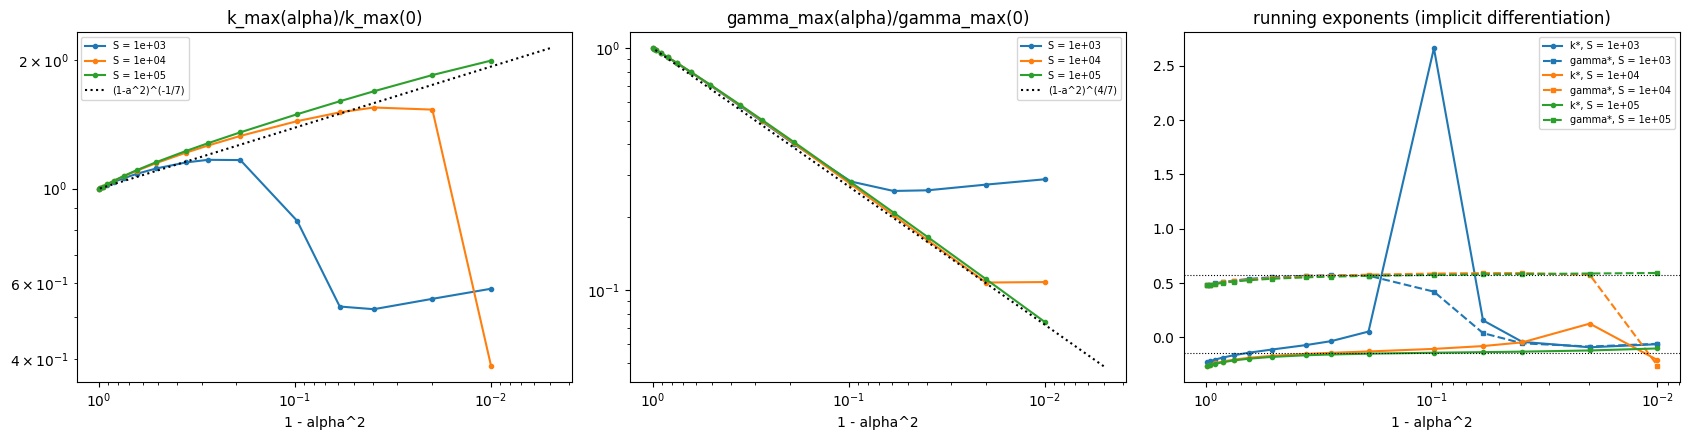

In [11]:
fig, axs = plt.subplots(1, 3, figsize=(17, 4.5))
for j, S in enumerate(R.S_KA):
    al = np.array(sorted(KA[S]))
    if not len(al) or 0.0 not in KA[S]:
        continue
    u = 1 - al**2
    k0, g0 = KA[S][0.0]["kmax"], KA[S][0.0]["gmax"]
    axs[0].loglog(u, [KA[S][a]["kmax"]/k0 for a in al], "o-", ms=3, color=f"C{j}", label=f"S = {S:.0e}")
    axs[1].loglog(u, [KA[S][a]["gmax"]/g0 for a in al], "o-", ms=3, color=f"C{j}", label=f"S = {S:.0e}")
    m = al > 0
    axs[2].semilogx(u[m], [KA[S][a]["slope_k_u"] for a in al[m]], "o-", ms=3, color=f"C{j}", label=f"k*, S = {S:.0e}")
    axs[2].semilogx(u[m], [KA[S][a]["slope_g_u"] for a in al[m]], "s--", ms=3, color=f"C{j}", label=f"gamma*, S = {S:.0e}")
uu = np.geomspace(5e-3, 1, 50)
axs[0].loglog(uu, uu**(-1/7), "k:", label="(1-a^2)^(-1/7)")
axs[1].loglog(uu, uu**(4/7), "k:", label="(1-a^2)^(4/7)")
for y in (-1/7, 4/7):
    axs[2].axhline(y, color="k", ls=":", lw=0.8)
for ax, t in zip(axs, ("k_max(alpha)/k_max(0)", "gamma_max(alpha)/gamma_max(0)",
                       "running exponents (implicit differentiation)")):
    ax.set_xlabel("1 - alpha^2"); ax.set_title(t); ax.legend(fontsize=7); ax.invert_xaxis()
plt.tight_layout()

In [12]:
# cross-checks: 1b-ref's 10-ka peak fits (T.peak_fit through its table) and rung 1b's 5-ka ridge fits
tab = U.shear_tables()
kas_ref = sorted({k for k, _ in tab})
RIDGE = {}
for S in U.S_RIDGE:
    try:
        RIDGE[S] = {a: U.ridge_fit(rows) for a, rows in U.ridge_results(S).items() if len(rows) == 5}
    except Exception as e:
        print("ridge read failed", S, e)
print("   S     alpha | Newton k*      g*/g*(0)   | 1b-ref peak fit k (+-)      g/g(0) | 1b ridge fit k (+-)        "
      "| (1-a^2)^(4/7)")
for S in R.S_KA:
    if 0.0 not in KA[S]:
        continue
    g00 = KA[S][0.0]["gmax"]
    pk0 = T.peak_fit(kas_ref, [complex(tab[(k, 0.0)][S]["value"]).real for k in kas_ref]) if S in (1e3, 1e4, 1e5) else None
    for al, r in sorted(KA[S].items()):
        s = f"  {S:.0e}  {al:5.3f} | {r['kmax']:.6f}  {r['gmax']/g00:.5f}   |"
        if pk0 is not None and all((k, al) in tab for k in kas_ref):
            pk = T.peak_fit(kas_ref, [complex(tab[(k, al)][S]["value"]).real for k in kas_ref])
            s += f" {pk[0]:.4f} ({pk[2]:.0e})  {pk[1]/pk0[1]:.5f} |"
        else:
            s += " "*33 + "|"
        rf = RIDGE.get(S, {}).get(al)
        s += f" {rf['kmax']:.4f} ({rf['kmax_err']:.0e}) {'in ' if rf['inside'] else 'OUT'} |" if rf else " "*25 + "|"
        print(s + f" {(1-al*al)**(4/7):.4f}")
print("\nrung 1b-ref's quoted gamma_max(alpha)/gamma_max(0) = 0.955, 0.80, 0.58, 0.28 at alpha = 0.3, 0.6, 0.8, 0.95")

   S     alpha | Newton k*      g*/g*(0)   | 1b-ref peak fit k (+-)      g/g(0) | 1b ridge fit k (+-)        | (1-a^2)^(4/7)
  1e+03  0.000 | 0.637613  1.00000   | 0.6353 (9e-03)  1.00000 |                         | 1.0000
  1e+03  0.100 | 0.639113  0.99520   |                                 |                         | 0.9943
  1e+03  0.200 | 0.643585  0.98053   |                                 |                         | 0.9769
  1e+03  0.300 | 0.650974  0.95510   | 0.6499 (8e-03)  0.95583 |                         | 0.9475
  1e+03  0.400 | 0.661259  0.91744   |                                 |                         | 0.9052
  1e+03  0.500 | 0.674530  0.86530   |                                 |                         | 0.8484
  1e+03  0.600 | 0.691046  0.79541   | 0.6872 (2e-03)  0.79583 |                         | 0.7749
  1e+03  0.700 | 0.711195  0.70262   |                                 |                         | 0.6806
  1e+03  0.800 | 0.734519  0.57792   | 0.7295 (1e-0

**Result (section 3).** *Convergence:* Newton converges in 3-6 eigen-solves (10 at one branch switch), with $|k_{pol}-k^*|/k\le2\times10^{-10}$. A full Newton solve at $2n_x$ moves $k^*$ by $\le6\times10^{-9}$ at all four check points (the $n_x/2$ estimate is the looser bound, up to $1.3\times10^{-5}$). Against the earlier fits: $k^*$ lies within the 10-$ka$ peak fits of rung 1b-ref (within their error bars) and $0.5$-$1.2\%$ above rung 1b's 5-$ka$ ridge fits (1-2.5 of their error bars, a systematic bias of the 5-point fit). The $\gamma^*/\gamma^*(0)$ ratios reproduce 1b-ref's to $\le2.4\times10^{-3}$.

*The followed maximum (high-$k$ branch):* $k^*$ *rises* with $\alpha$, as the paper's $k_{tr}\propto(\alpha/(1-\alpha^2))^{1/7}$ does: $0.336\to0.669$ from $\alpha=0$ to $0.995$ at $S=10^5$. The running exponent $d\ln\gamma^*/d\ln(1-\alpha^2)$ climbs smoothly from $0.48$ at $\alpha=0.1$, crosses the paper's $4/7$ between $\alpha=0.9$ and $0.95$, and reaches $0.5925$ at $\alpha=0.995$ ($S=10^5$). That agrees with rung 1b's ridge exponent, which peaks at $\approx0.59$ and approaches $4/7$ from above as $S$ grows. Prefactor-free, $\gamma^*/\gamma^*(0)=0.0738$ against $(1-\alpha^2)^{4/7}=0.0719$ at $\alpha=0.995$. The $k$ exponent $d\ln k^*/d\ln(1-\alpha^2)$ goes from $-0.27$ to $-0.10$ and crosses the paper's $-1/7$ between $\alpha=0.9$ and $0.95$. It does not sit on that value, because the asymptote needs $1-\alpha^2\ll\alpha$ *and* $\delta_{in}/a\ll1$, and $\delta_{in}/a$ is still $0.11$ at $\alpha=0.995$, $S=10^5$. These are smooth versions of the paper's fig. 3 curves, which were grid-scanned.

*Branch switch:* $\gamma(k)$ has a second, low-$k$ maximum, and at the lowest $S$ and highest $\alpha$ it takes over. At $S=10^3$, $k^*$ falls $0.744\to0.536\to0.338$ over $\alpha=0.9$, $0.95$, $0.97$, then stays at $ka=0.33$-$0.37$ to $\alpha=0.995$, where $\gamma^*/\gamma^*(0)$ *rises* again with $\alpha$ ($0.257\to0.287$). At $S=10^4$, $\alpha=0.995$, $k^*$ jumps $0.713\to0.179$. That switch is unambiguous: Newton's iterates climb $\gamma$ monotonically from $2.31\times10^{-3}$ at $ka=0.668$ to $3.38\times10^{-3}$ at $0.179$, so no maximum survives near the old $k^*$, and rung 1b's ridge fit at that point flags its peak as outside its fitted window. Both continuation chains in $\alpha$ therefore **jump** between two maxima; they are not following a single smooth curve. The continuation seed trust region added after the first campaign is what lets them cross. Caveats: (i) at $S=10^3$, $\alpha\ge0.97$, the solve starts from the clipped seed $k^*/2$, so whether a lower high-$k$ maximum survives there is not tested; (ii) this low-$k$ mode lives at $\delta_{in}/a\approx0.38$-$0.65$ (at $\alpha=0.995$), outside every thin-layer theory, and it is **not identified here** (section 4 gives its $S$ scaling).

### 4. $k_{max}(S)$ and $\gamma_{max}(S)$ at fixed $\alpha$ (the paper's fig. 4), and the running slopes

Newton at $S=10^3\ldots10^5$ ($10^6$ at $\alpha=0$ if the optional phase ran), continued in $S$ with the previous solution's
implicit slopes. The **running** exponents $d\ln k^*/d\ln S=\eta\gamma_{k\eta}/(k^*\gamma_{kk})$ and
$d\ln\gamma^*/d\ln S=-(\eta/\gamma^*)\partial_\eta\gamma$ come from each solution alone; they are checked against the
secant slopes between neighbouring $S$, and at $\alpha=0$ against the exact relation's running slopes. The paper's
asymptotes are $-1/7$ and $-3/7$ at every $\alpha$ (section 0); the shear regime also needs $\delta_{in}/a\ll1$, printed.

In [13]:
print("  alpha    S    | k*          gamma*         | d ln k*/d ln S: implicit  secant  theory(a=0) | "
      "d ln g*/d ln S: implicit  secant  theory | delta_in/a  grid dk/k")
for al in R.ALPHA_KS:
    Ss = sorted(KS[al])
    for i, S in enumerate(Ss):
        r = KS[al][S]
        sec_k = sec_g = np.nan
        if 0 < i < len(Ss) - 1:
            a_, b_ = KS[al][Ss[i - 1]], KS[al][Ss[i + 1]]
            L = np.log(Ss[i + 1]/Ss[i - 1])
            sec_k, sec_g = np.log(b_["kmax"]/a_["kmax"])/L, np.log(b_["gmax"]/a_["gmax"])/L
        tk, tg = R.theory_kmax_slopes(S) if al == 0 else (np.nan, np.nan)
        d = R.delta_in(S, r["kmax"], al) if al > 0 else np.nan
        print(f"  {al:5.3f}  {S:.0e} | {r['kmax']:.8f}  {r['gmax']:.8e} |        {r['slope_k_S']:+.5f}   {sec_k:+.5f}  "
              f"{tk:+.5f}    |          {r['slope_g_S']:+.5f}   {sec_g:+.5f}  {tg:+.5f} |  {d:.3f}     "
              f"{r['grid_dk']/r['kmax']:+.1e}")

  alpha    S    | k*          gamma*         | d ln k*/d ln S: implicit  secant  theory(a=0) | d ln g*/d ln S: implicit  secant  theory | delta_in/a  grid dk/k
  0.000  1e+03 | 0.63761256  7.92765475e-02 |        -0.12923   +nan  -0.13661    |          -0.38521   +nan  -0.42731 |  nan     +6.3e-13
  0.000  2e+03 | 0.58175392  6.03998767e-02 |        -0.13486   -0.13509  -0.13859    |          -0.39865   -0.39949  -0.42774 |  nan     +2.4e-08
  0.000  5e+03 | 0.51301799  4.16785420e-02 |        -0.13911   -0.13845  -0.14034    |          -0.41019   -0.40847  -0.42810 |  nan     -2.4e-14
  0.000  1e+04 | 0.46555084  3.12989401e-02 |        -0.14087   -0.14075  -0.14121    |          -0.41584   -0.41555  -0.42828 |  nan     +1.1e-08
  0.000  2e+04 | 0.42207920  2.34275251e-02 |        -0.14188   -0.14191  -0.14180    |          -0.41974   -0.41999  -0.42839 |  nan     -8.3e-15
  0.000  5e+04 | 0.37048919  1.59209482e-02 |        -0.14258   -0.14247  -0.14228    |          -0.42312   -0.42

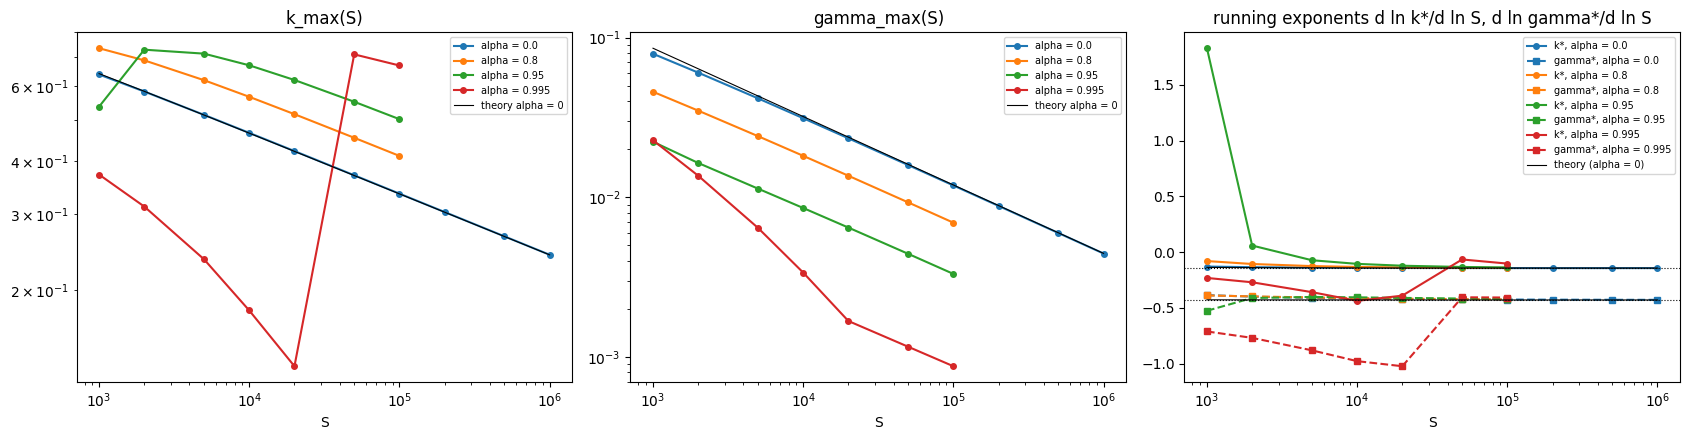

In [14]:
fig, axs = plt.subplots(1, 3, figsize=(17, 4.5))
for j, al in enumerate(R.ALPHA_KS):
    Ss = np.array(sorted(KS[al]))
    if not len(Ss):
        continue
    axs[0].loglog(Ss, [KS[al][S]["kmax"] for S in Ss], "o-", ms=4, color=f"C{j}", label=f"alpha = {al}")
    axs[1].loglog(Ss, [KS[al][S]["gmax"] for S in Ss], "o-", ms=4, color=f"C{j}", label=f"alpha = {al}")
    axs[2].semilogx(Ss, [KS[al][S]["slope_k_S"] for S in Ss], "o-", ms=4, color=f"C{j}", label=f"k*, alpha = {al}")
    axs[2].semilogx(Ss, [KS[al][S]["slope_g_S"] for S in Ss], "s--", ms=4, color=f"C{j}", label=f"gamma*, alpha = {al}")
SS = np.geomspace(1e3, 1e6, 40)
th = np.array([R.theory_kmax(S) for S in SS])
axs[0].loglog(SS, th[:, 0], "k-", lw=0.8, label="theory alpha = 0")
axs[1].loglog(SS, th[:, 1], "k-", lw=0.8, label="theory alpha = 0")
axs[2].semilogx(SS, [R.theory_kmax_slopes(S)[0] for S in SS], "k-", lw=0.8, label="theory (alpha = 0)")
axs[2].semilogx(SS, [R.theory_kmax_slopes(S)[1] for S in SS], "k-", lw=0.8)
for y in (-1/7, -3/7):
    axs[2].axhline(y, color="k", ls=":", lw=0.8)
for ax, t in zip(axs, ("k_max(S)", "gamma_max(S)", "running exponents d ln k*/d ln S, d ln gamma*/d ln S")):
    ax.set_xlabel("S"); ax.set_title(t); ax.legend(fontsize=7)
plt.tight_layout()

In [15]:
# alpha = 0: Newton against the exact relation (finite-S correction), and the 2 nx re-solves
if 0.0 in KS:
    print("alpha = 0:   S   | k*/k_th - 1     gamma*/gamma_th")
    for S, r in sorted(KS[0.0].items()):
        kth, gth = R.theory_kmax(S)
        print(f"          {S:.0e} |  {r['kmax']/kth - 1:+.4e}     {r['gmax']/gth:.6f}")
print("\nnx doubling of k*: the kmax_alpha solution at nx against a full Newton at 2 nx")
for (S, al), r2 in G2.items():
    r1 = KA.get(S, {}).get(al)
    if r1:
        print(f"  S={S:.0e} alpha={al}: nx {r1['nx']} -> {r2['nx']}: d k*/k* = {r2['kmax']/r1['kmax'] - 1:+.2e}, "
              f"d gamma*/gamma* = {r2['gmax']/r1['gmax'] - 1:+.2e}; the nx/2 estimate was {r1['grid_dk']/r1['kmax']:+.1e}")

alpha = 0:   S   | k*/k_th - 1     gamma*/gamma_th
          1e+03 |  -4.8128e-03     0.923250
          2e+03 |  -1.0919e-03     0.946047
          5e+03 |  +1.0256e-03     0.966235
          1e+04 |  +1.5337e-03     0.976337
          2e+04 |  +1.6001e-03     0.983422
          5e+04 |  +1.4010e-03     0.989640
          1e+05 |  +1.1827e-03     0.992737
          2e+05 |  +9.6562e-04     0.994904
          5e+05 |  +7.1528e-04     0.996807
          1e+06 |  +5.6092e-04     0.997755

nx doubling of k*: the kmax_alpha solution at nx against a full Newton at 2 nx
  S=1e+04 alpha=0.0: nx 4096 -> 8192: d k*/k* = -1.81e-12, d gamma*/gamma* = +3.33e-15; the nx/2 estimate was +1.1e-08
  S=1e+05 alpha=0.0: nx 8192 -> 16384: d k*/k* = -1.25e-13, d gamma*/gamma* = -4.12e-14; the nx/2 estimate was +1.3e-05
  S=1e+05 alpha=0.8: nx 8192 -> 16384: d k*/k* = -4.81e-14, d gamma*/gamma* = -1.27e-12; the nx/2 estimate was +4.8e-12
  S=1e+05 alpha=0.99: nx 8192 -> 16384: d k*/k* = +5.76e-09, d gamma*/

**Result (section 4).** *$\alpha=0$:* the running slopes from a single solution (implicit, $\eta\gamma_{k\eta}/(k^*\gamma_{kk})$ and $-(\eta/\gamma^*)\partial_\eta\gamma$) agree with the secant slopes between neighbouring $S$ to $\le7\times10^{-4}$ ($k$) and $\le1.7\times10^{-3}$ ($\gamma$). At $S=10^5$ they are $-0.1428$ and $-0.4248$, against the exact relation's running $-0.1425$ and $-0.4285$ and the asymptotes $-1/7=-0.1429$ and $-3/7=-0.4286$. $k^*$ is within $0.5\%$ of the theory maximum at every $S$. $\gamma^*/\gamma_{th}$ rises from $0.923$ to $0.9927$ over $S=10^3$-$10^5$, so the finite-$S$ deficit falls by $10.5\times$ over two decades, roughly $\propto S^{-1/2}$. The high-$S$ phase extends this to $S=10^6$ (resolution-converged: $n_x/2$ moves $k^*$ by $\le1.2\times10^{-5}$). There $\gamma^*/\gamma_{th}=0.99776$, still on the $S^{-1/2}$ trend, and the $\gamma$ slope reaches $-0.42744$ against the exact relation's $-0.42858$. The $k$ slope levels off at $-0.14302$, $1.7\times10^{-4}$ steeper than $-1/7$, while the exact relation's running slope ($-0.14282$) approaches $-1/7$ from above. The gap between the two (from $3.2\times10^{-4}$ at $10^5$ to $2.0\times10^{-4}$ at $10^6$) is the finite-$S$ correction to $k^*$ ($k^*/k_{th}-1$ falls from $1.18\times10^{-3}$ to $5.6\times10^{-4}$). As it decays, the eigenvalue slope must turn back to $-1/7$: the overshoot is transient, not a different exponent.

*$\alpha=0.8$:* the same asymptotes, approached almost as fast: $-0.1414$ and $-0.4234$ at $S=10^5$, lagging the $\alpha=0$ slopes by $\le2\times10^{-3}$, while $\delta_{in}/a$ falls from $0.145$ to $0.038$. This **directly confirms the paper's statement that the $S$-exponents of the maximum are independent of $\alpha$**: they come out at $-1/7$ and $-3/7$ whether or not shear is present. *$\alpha=0.95$:* on the high-$k$ branch from $S=2\times10^3$, approaching more slowly ($-0.137$, $-0.419$ at $10^5$). At $S=10^3$ the maximum is nearly flat on the way to the switch ($\gamma_{kk}\to0$, implicit $d\ln k^*/d\ln S=+1.83$).

*$\alpha=0.995$:* for $S\le2\times10^4$ the maximum is the low-$k$ branch of section 3, and it does not scale like tearing. Its running $d\ln\gamma^*/d\ln S$ steepens from $-0.71$ to $-1.02$ and its $d\ln k^*/d\ln S$ from $-0.23$ to $-0.44$, with $\delta_{in}/a=0.65\to0.34$. Because it decays faster in $S$ than the tearing maximum, it hands over between $S=2\times10^4$ and $5\times10^4$. At $5\times10^4$, Newton climbs $\gamma$ monotonically from $ka=0.093$ to the high-$k$ maximum at $0.711$. On that branch, the slopes at $5\times10^4$-$10^5$ ($-0.066$/$-0.103$ for $k$, $-0.405$/$-0.407$ for $\gamma$) are still far from the asymptotes. The secant slopes across the switch ($+0.86$, $+1.01$) compare two different modes and mean nothing. 

### 5. Summary

* **Rung 2's sensitivities work as physics tools.** $\partial_\eta\gamma$ and $\partial_k\gamma$ (through the overrides seam, $k$ itself an override) converge to eigenvalue finite differences at order 2, and one right/left pair per solve gives every running exponent along the dispersion curve. There is no sweep in $S$.
* **$q_S(k)$ along the dispersion curve:** at $\alpha=0$ it converges onto the exact relation's analytic exponent as $S$ grows (gap $\le0.005$ for $ka\le1$ at $S=10^5$). With shear, the large-$k$ plateau moves from FKR's $-3/5$ toward the shear constant-$\psi$ $-1/2$ ($-0.522$ at $\alpha=0.8$, $S=10^5$), ordered by the paper's $\lambda/\alpha$. At fixed $k$, the $S$-exponent identifies the shear regime.
* **$k_{max}$ by Newton** ($\partial_k\gamma=0$, 3-6 solves, resolution-converged to $\le6\times10^{-9}$) gives smooth $k_{max}(\alpha)$ and $\gamma_{max}(\alpha)$ in place of the paper's grid-scanned figs. 3-4. They agree with 1b-ref's peak fits and rung 1b's ridge fits. $d\ln\gamma^*/d\ln(1-\alpha^2)$ crosses $4/7$ between $\alpha=0.9$ and $0.95$ and reaches $0.59$, consistent with $4/7$ approached from above.
* **$S$-scaling of the maximum:** at $\alpha=0$ and $0.8$ the running slopes reach $-0.143/-0.141$ and $-0.425/-0.423$ at $S=10^5$, on their way to $-1/7$ and $-3/7$. At $\alpha=0$ they reach $-0.1430$ and $-0.4274$ at $S=10^6$, where $\gamma^*$ is within $0.22\%$ of the exact theory. The exponents are the same with and without shear, as the paper says, so it is the $\alpha$-dependence and $q_S$ at fixed $k$ that discriminate the regimes.
* **New: a second, low-$k$ maximum.** At $\alpha\gtrsim0.95$ and low $S$ ($S=10^3$; $S\le2\times10^4$ at $\alpha=0.995$), it takes over from the tearing maximum. It has $ka\approx0.13$-$0.37$, $\delta_{in}/a\approx0.3$-$0.65$, $d\ln\gamma^*/d\ln S\approx-0.7$ to $-1.0$, and a growth rate that rises again as $\alpha\to1$. $k_{max}(\alpha)$ and $k_{max}(S)$ jump between the two branches. The mode is not identified here; it is the open item from this notebook (being identified in `tearing-lowk-branch.ipynb`).